# Анализ веб-журнала

В этой практике текстовые строки журнала превращаются в проверенную таблицу. Затем рассчитываются доли ответов, исследуется хвост задержек и строятся временные агрегаты. Все ячейки выполняются заранее, а результаты остаются рядом с кодом.

Формат записи задан полями ip, timestamp, method, path, status, response_bytes, response_ms, browser. У файла нет заголовка; значение двух последних чисел как байтов и миллисекунд является учебным соглашением. IP не обозначает человека или сессию. Синтетический файл не доказывает стабильный SLO реальной службы, а метка браузера без связанных событий не позволяет измерить конверсию.

Сначала проверяются структура и качество. Интерпретация агрегатов опирается на результаты этих проверок.

Качество данных входит в смысл любого итогового числа. Если часть строк не удалось прочитать, доля ответов относится только к принятому подмножеству, и размер исключённой части нужно сообщать отдельно. Пустые интервалы времени также нельзя превращать в нулевую задержку: запросов в них не было, а значит среднее отсутствует. При развороте параметров URL одна запись способна дать несколько строк, поэтому перед новым подсчётом надо снова назвать единицу наблюдения. Эти правила важнее выбора конкретной функции Pandas: они сохраняют связь между исходной записью, преобразованием и интерпретацией таблицы. Проверка результативности разборщика строится на отдельной копии с известными повреждениями.

## Структура и качество

Разбор текста и проверка смысла полей предшествуют расчёту метрик. Число отклонённых строк сохраняется.

**Загрузить сырой журнал**

Журнал начинается как текст, а не как готовая таблица. Журнал читается отдельно строками, а файл на диске остаётся неизменным. Первые пять строк служат образцом формата, но не представляют распределение всего года. Каталог данных ищется по точному файлу data/orders.csv среди рабочего каталога и его родителей, поэтому ноутбук работает из папки модуля. При отсутствии нужного журнала возникает явная ошибка вместо тихой подмены источника. Пока не выполнен разбор, ещё нет надёжных колонок времени или задержки, и считать метрики преждевременно.

In [1]:
# Шаг 03.01 — Загрузить сырой журнал
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

data_dir = next((p / 'data' for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'data' / 'orders.csv').is_file()), None)
if data_dir is None or not (data_dir / 'access.log').is_file():
    raise FileNotFoundError('Нужны data/orders.csv и data/access.log')
raw = pd.Series((data_dir / 'access.log').read_text(encoding='utf-8').splitlines(), name='raw_line')
print('Строк:', len(raw))
display(raw.head().to_frame())

Строк: 300000


,raw_line
0,10.7.230.111 2026-07-02T13:37:56 GET / 200 737...
1,10.145.173.29 2026-04-19T09:23:49 GET /search ...
2,10.39.59.223 2026-12-03T10:20:16 GET /checkout...
3,10.250.232.47 2026-10-04T22:43:27 GET /search ...
4,10.223.234.9 2026-02-25T18:41:40 GET /help 200...


**Внести контролируемые дефекты**

Для проверки процедуры пять плохих строк добавляются только к копии Series. Среди них есть обрывок, нечисловой код, невозможная дата, отрицательная задержка и код вне HTTP-диапазона. Часть нарушений обнаружится регулярным выражением, часть — лишь после преобразования типов. Это показывает, почему одна проверка формата недостаточна. Исходный access.log остаётся неизменным, поэтому следующий запуск видит тот же набор данных. Контролируемые дефекты позволяют проверить, что процедура действительно различает структурную ошибку и неверное значение, не ограничиваясь молчаливым отбором правдоподобных строк.

In [2]:
# Шаг 03.02 — Внести контролируемые дефекты
bad_examples = pd.Series([
    'обрывок строки',
    '10.0.0.1 2026-07-02T13:37:56 GET / 5xx 100 12 Chrome',
    '10.0.0.2 2026-99-02T13:37:56 GET / 200 100 12 Chrome',
    '10.0.0.3 2026-07-02T13:37:56 GET / 200 100 -12 Chrome',
    '10.0.0.4 2026-07-02T13:37:56 GET / 999 100 12 Chrome',
], name='raw_line')
work_lines = pd.concat([raw, bad_examples], ignore_index=True)
print('Исходных:', len(raw), 'добавлено:', len(bad_examples), 'в копии:', len(work_lines))
display(work_lines.tail().to_frame())

Исходных: 300000 добавлено: 5 в копии: 300005


,raw_line
300000,обрывок строки
300001,10.0.0.1 2026-07-02T13:37:56 GET / 5xx 100 12 ...
300002,10.0.0.2 2026-99-02T13:37:56 GET / 200 100 12 ...
300003,10.0.0.3 2026-07-02T13:37:56 GET / 200 100 -12...
300004,10.0.0.4 2026-07-02T13:37:56 GET / 999 100 12 ...


**Извлечь именованные поля**

Формат задаётся восемью именованными группами регулярного выражения. Имена групп становятся колонками результата, а якоря начала и конца исключают частичное совпадение внутри повреждённой строки. Сначала проверяется только структура: непробельные текстовые токены и запись числа цифрами. Выражение не умеет подтвердить реальность даты или корректность HTTP-кода. Оно также не доказывает, что IP — настоящий сетевой адрес. Трактовка двух последних чисел как байтов и миллисекунд остаётся договорённостью учебного примера. Семантические ограничения будут проверены следующим шагом.

In [3]:
# Шаг 03.03 — Извлечь именованные поля
pattern = (r'^(?P<ip>\S+) (?P<timestamp>\S+) (?P<method>[A-Z]+) '
           r'(?P<path>\S+) (?P<status>\d+) (?P<response_bytes>-?\d+) '
           r'(?P<response_ms>-?\d+) (?P<browser>\S+)$')
parsed = work_lines.str.extract(pattern)
print('Размер таблицы:', parsed.shape)
display(parsed.head())

Размер таблицы: (300005, 8)


,ip,timestamp,method,path,status,response_bytes,response_ms,browser
0,10.7.230.111,2026-07-02T13:37:56,GET,/,200,73726,52,Chrome
1,10.145.173.29,2026-04-19T09:23:49,GET,/search,200,41170,60,Safari
2,10.39.59.223,2026-12-03T10:20:16,GET,/checkout,200,77741,130,Edge
3,10.250.232.47,2026-10-04T22:43:27,GET,/search,200,61392,22,Chrome
4,10.223.234.9,2026-02-25T18:41:40,GET,/help,200,65666,75,Firefox


**Показать неразобранные строки**

Если полное совпадение отсутствует, str.extract возвращает пропуски во всех извлечённых полях. Индекс сохраняется, поэтому выводится исходный текст проблемной записи. Это помогает увидеть причину: потерянный разделитель, неожиданный токен или новый вариант формата. Молчаливое удаление брака создало бы отчёт с неизвестным охватом. Здесь подсчитываются неразобранные строки и показываются примеры без попытки исправить их догадками. Строки, совпавшие с шаблоном, пока не признаны корректными: невозможная дата и отрицательная длительность могут пройти эту ступень.

In [4]:
# Шаг 03.04 — Показать неразобранные строки
unmatched = parsed.isna().all(axis=1)
print('Не прошли шаблон:', int(unmatched.sum()))
display(work_lines[unmatched].to_frame().head(10))

Не прошли шаблон: 2


,raw_line
300000,обрывок строки
300001,10.0.0.1 2026-07-02T13:37:56 GET / 5xx 100 12 ...


**Проверить типы и диапазоны**

После структурного разбора timestamp преобразуется в datetime, а три числовых поля — в числовые типы. Невозможная дата становится NaT. Дополнительно проверяются HTTP-код в диапазоне 100–599, неотрицательность байтов и задержки. Это минимальные смысловые ограничения, а не полная проверка протокола. Отрицательная задержка успешно превращается в число, но противоречит принятому смыслу поля. Отдельные флаги сообщают, какая именно проверка сработала. В настоящем сервисе допустимые значения определялись бы официальной схемой журнала; здесь они сформулированы открыто и поддаются проверке.

In [5]:
# Шаг 03.05 — Проверить типы и диапазоны
parsed['timestamp'] = pd.to_datetime(parsed['timestamp'], errors='coerce')
for col in ['status', 'response_bytes', 'response_ms']:
    parsed[col] = pd.to_numeric(parsed[col], errors='coerce')
quality = pd.DataFrame({
    'структура': unmatched,
    'дата': parsed['timestamp'].isna() & ~unmatched,
    'код': ~parsed['status'].between(100, 599) & ~unmatched,
    'байты': (parsed['response_bytes'].isna() | (parsed['response_bytes'] < 0)) & ~unmatched,
    'задержка': (parsed['response_ms'].isna() | (parsed['response_ms'] < 0)) & ~unmatched,
})
display(quality.sum().to_frame('строк с дефектом'))
display(work_lines[quality.any(axis=1)].to_frame().tail(10))

,строк с дефектом
структура,2
дата,1
код,1
байты,0
задержка,1


,raw_line
300000,обрывок строки
300001,10.0.0.1 2026-07-02T13:37:56 GET / 5xx 100 12 ...
300002,10.0.0.2 2026-99-02T13:37:56 GET / 200 100 12 ...
300003,10.0.0.3 2026-07-02T13:37:56 GET / 200 100 -12...
300004,10.0.0.4 2026-07-02T13:37:56 GET / 999 100 12 ...


**Сформировать чистую таблицу**

Для агрегатов используются строки без выявленных дефектов. Повреждённые значения не заменяются нулём или медианой, потому что это создало бы вымышленные наблюдения. Числовые поля преобразуются к целым типам, записи сортируются по timestamp. Сверка принятого и отклонённого количества с размером рабочей копии предотвращает тихую потерю строк. Она не доказывает идеальную корректность каждого поля, зато делает охват расчёта явным. Добавленные плохие примеры исключены из метрик, а исходный журнал по-прежнему не менялся. Следующие выводы относятся именно к этой таблице.

In [6]:
# Шаг 03.06 — Сформировать чистую таблицу
valid_mask = ~quality.any(axis=1)
log = parsed.loc[valid_mask].copy()
for col in ['status', 'response_bytes', 'response_ms']:
    log[col] = log[col].astype('int64')
log = log.sort_values('timestamp').reset_index(drop=True)
assert len(log) + int((~valid_mask).sum()) == len(work_lines)
print('Принято:', len(log), 'отклонено:', int((~valid_mask).sum()))
display(log.head())

Принято: 300000 отклонено: 5


,ip,timestamp,method,path,status,response_bytes,response_ms,browser
0,10.40.127.22,2026-01-01 00:05:55,GET,/account,200,33999,28,Chrome
1,10.142.3.90,2026-01-01 00:10:12,GET,/product/1663,200,41180,61,Firefox
2,10.110.28.55,2026-01-01 00:11:27,GET,/,200,33504,314,Chrome
3,10.102.15.173,2026-01-01 00:11:43,GET,/checkout,200,30171,165,Chrome
4,10.35.128.123,2026-01-01 00:11:48,GET,/search,200,49470,525,Edge


Получена аналитическая таблица с известным числом принятых и отклонённых записей.

## Ответы и задержки

Сопоставляются классы ответов и разные положения в распределении задержки. Все доли имеют явный знаменатель.

**Посчитать классы ответов**

Код ответа относится к конкретному запросу. Классы 2xx, 3xx, 4xx и 5xx отвечают на разные вопросы; код 4xx нельзя автоматически назвать сбоем сервера. Рассчитываются абсолютное число ответов каждого класса и доля среди всех валидных запросов. Абсолютное число показывает наблюдавшуюся нагрузку, доля позволяет сравнить классы. Синтетический файл, даже охватывающий календарный год, не служит доказательством стабильного SLO реального сервиса. Для такого вывода нужны договорённая метрика, полнота потока и правила исключений. Поэтому выводы ограничиваются описанием строк данного набора.

In [7]:
# Шаг 03.07 — Посчитать классы ответов
log['status_class'] = (log['status'] // 100).astype(str) + 'xx'
status_table = log['status_class'].value_counts().sort_index().rename_axis('класс').to_frame('запросов')
status_table['доля_всех'] = status_table['запросов'] / len(log)
display(status_table)

,запросов,доля_всех
класс,,
2xx,269705,0.899017
3xx,12110,0.040367
4xx,15117,0.050390
5xx,3068,0.010227


**Разделить доли ошибок**

Формулу error rate задают до вычисления. Доля 5xx — число кодов 500–599, делённое на все валидные запросы; доля 4xx строится с тем же знаменателем. Условная доля 5xx среди ответов 4xx+5xx имеет другой знаменатель и отвечает на другой вопрос. Она может быть намного больше, хотя числитель не менялся. Исключённые повреждённые строки не считаются ни успехами, ни ошибками; их количество показано при валидации. Подписи каждой строки результата явно содержат числитель и знаменатель. Это защищает от расплывчатого выражения «процент ошибок» без определения.

In [8]:
# Шаг 03.08 — Разделить доли ошибок
n_all = len(log)
n_4xx = int(log['status'].between(400, 499).sum())
n_5xx = int(log['status'].between(500, 599).sum())
rates = pd.Series({
    '5xx / все': n_5xx / n_all,
    '4xx / все': n_4xx / n_all,
    '5xx / (4xx + 5xx)': n_5xx / (n_4xx + n_5xx) if n_4xx + n_5xx else np.nan,
})
print(f'Все={n_all}, 4xx={n_4xx}, 5xx={n_5xx}')
display(rates.to_frame('доля'))

Все=300000, 4xx=15117, 5xx=3068


,доля
5xx / все,0.010227
4xx / все,0.050390
5xx / (4xx + 5xx),0.168710


**Сравнить среднее и перцентили**

Средняя задержка чувствительна к редким долгим ответам. Перцентили описывают положение значения в распределении: p50 — медиана, p95 и p99 всё дальше показывают границы хвоста. Они выводятся рядом со средним и максимумом. Эти значения относятся только к учебному соглашению, что последнее число в строке означает миллисекунды. Они не измеряют время отображения страницы в браузере или полный сетевой путь. Из-за совпадающих дискретных значений доля строк строго выше p95 может быть не равна ровно пяти процентам. Несколько характеристик распределения дают более полную картину, чем одна выбранная цифра.

In [9]:
# Шаг 03.09 — Сравнить среднее и перцентили
latency = log['response_ms']
latency_summary = pd.Series({
    'среднее_мс': latency.mean(),
    'p50_мс': latency.quantile(.50),
    'p95_мс': latency.quantile(.95),
    'p99_мс': latency.quantile(.99),
    'максимум_мс': latency.max(),
})
display(latency_summary.to_frame('значение'))

,значение
среднее_мс,123.39687
p50_мс,89.00000
p95_мс,336.00000
p99_мс,580.00000
максимум_мс,3059.00000


**Показать хвост на гистограмме**

Для запросов строго выше p95 отдельно выводятся их число, доля и средняя задержка. Доля не обязана быть ровно пять процентов из-за дискретных значений. Гистограмма ограничивается значением p99, чтобы основная масса была видна без чрезмерно длинной оси. Отсечение прямо указано в названии: график не содержит самых крайних значений. Поэтому рядом остаются числовой максимум и средняя задержка хвоста. Такой рисунок помогает увидеть асимметрию, но не заменяет полную статистику. Нельзя объявлять отсутствие значений за правой границей просто потому, что они не попали в рисунок.

Выше p95: 14863 доля: 0.049543333333333335 среднее хвоста: 494.9462423467671


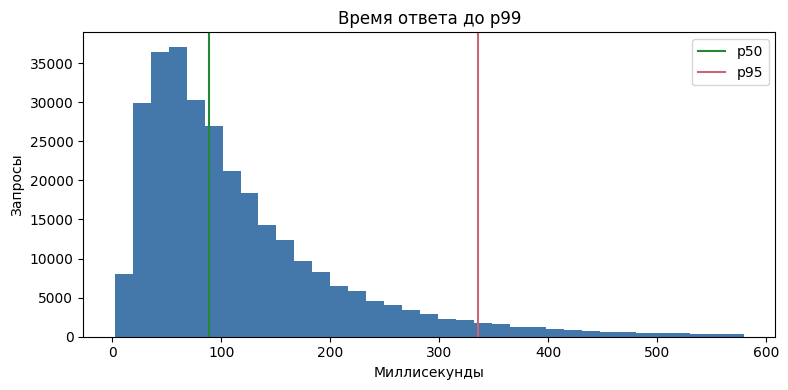

In [10]:
# Шаг 03.10 — Показать хвост на гистограмме
p95 = latency.quantile(.95)
tail = latency[latency > p95]
print('Выше p95:', len(tail), 'доля:', len(tail) / len(latency), 'среднее хвоста:', tail.mean())
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(latency[latency <= latency.quantile(.99)], bins=35, color='#4477aa')
ax.axvline(latency.median(), color='#228833', label='p50')
ax.axvline(p95, color='#cc6677', label='p95')
ax.set(title='Время ответа до p99', xlabel='Миллисекунды', ylabel='Запросы')
ax.legend()
fig.tight_layout()
plot_dir = Path.cwd() / 'outputs'
plot_dir.mkdir(exist_ok=True)
fig.savefig(plot_dir / '03_задержки.png', dpi=130)
plt.show()
plt.close(fig)

**Найти популярные пути**

Частота path показывает, к каким разделам относятся запросы. Подсчитываются значения и доля от всех валидных строк. Это популярность обращений, а не число посетителей: один клиент может сделать много запросов, автоматический процесс тоже, а один IP может принадлежать многим людям за прокси. Разные IP также не доказывают разных людей. Поэтому из этого поля нельзя без дополнительных правил восстановить сессии или аудиторию. Путь остаётся полезным уровнем операционного анализа, если вывод формулируется точно. В таблице единица наблюдения явно названа запросом, чтобы число не превратилось в мнимую посещаемость.

In [11]:
# Шаг 03.11 — Найти популярные пути
pages = log['path'].value_counts().rename_axis('путь').to_frame('запросов')
pages['доля_всех'] = pages['запросов'] / len(log)
display(pages.head(10))

,запросов,доля_всех
путь,,
/,60168,0.200560
/catalog,53882,0.179607
/search,44950,0.149833
/cart,24190,0.080633
/account,17791,0.059303
/promo,14886,0.049620
/checkout,11982,0.039940
/help,6031,0.020103
/product/1153,52,0.000173


**Сравнить метки браузеров**

Поле browser в строке можно сгруппировать так же, как путь. Получается распределение меток среди запросов, но не подтверждённые свойства реальных браузеров каждого человека. Из этого нельзя вычислить конверсию: нужны события входа и целевого действия, общий идентификатор и согласованные правила атрибуции. Деление количества запросов checkout на количество строк Chrome не создаст бизнес-воронку, потому что единицы наблюдения не совпадают. На графике вертикальная ось прямо названа количеством запросов. Такая осторожность предотвращает неправомерные выводы даже при технически безошибочном коде группировки.

,запросов,доля_всех
браузер,,
Chrome,134910,0.449700
Safari,59776,0.199253
YaBrowser,45279,0.150930
Firefox,23964,0.079880
Edge,21003,0.070010
bot,15068,0.050227


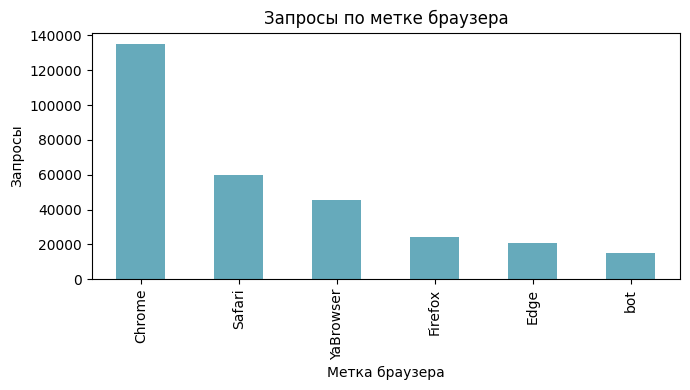

In [12]:
# Шаг 03.12 — Сравнить метки браузеров
browsers = log['browser'].value_counts().rename_axis('браузер').to_frame('запросов')
browsers['доля_всех'] = browsers['запросов'] / len(log)
display(browsers)
fig, ax = plt.subplots(figsize=(7, 4))
browsers['запросов'].plot.bar(ax=ax, color='#66aabb')
ax.set(title='Запросы по метке браузера', xlabel='Метка браузера', ylabel='Запросы')
fig.tight_layout()
fig.savefig(plot_dir / '03_браузеры.png', dpi=130)
plt.show()
plt.close(fig)

Сводки описывают запросы синтетического файла, а не эксплуатационную гарантию сервиса.

## Временные окна

Регулярная сетка включает минуты без событий. Ноль запросов и отсутствие определённой доли различаются.

**Посчитать дневные показатели**

Timestamp позволяет объединять запросы по календарным дням. В одной таблице рассчитываются объём, количество 5xx и средняя задержка. Дневная доля 5xx рассчитывается делением ошибок на запросы этого же дня: два дня с одинаковым числом ошибок могут иметь разные доли из-за нагрузки. В исходных строках нет часового пояса, поэтому это календарь записанного времени, а не доказанное UTC. Смещение не назначается задним числом. Дневной ряд помогает видеть динамику, но сглаживает внутридневные всплески. Даже годовая последовательность синтетических наблюдений не подтверждает стабильный SLO действующей службы.

In [13]:
# Шаг 03.13 — Посчитать дневные показатели
log['day'] = log['timestamp'].dt.floor('D')
daily = log.groupby('day').agg(
    запросов=('status', 'size'),
    серверных_ошибок=('status', lambda s: s.between(500, 599).sum()),
    среднее_мс=('response_ms', 'mean'))
daily['доля_5xx'] = daily['серверных_ошибок'] / daily['запросов']
print('Дней:', len(daily), 'от:', daily.index.min(), 'до:', daily.index.max())
display(daily.head())

Дней: 365 от: 2026-01-01 00:00:00 до: 2026-12-31 00:00:00


,запросов,серверных_ошибок,среднее_мс,доля_5xx
day,,,,
2026-01-01,799,6,122.674593,0.007509
2026-01-02,825,11,122.814545,0.013333
2026-01-03,819,3,127.387057,0.003663
2026-01-04,839,11,133.144219,0.013111
2026-01-05,824,6,115.478155,0.007282


**Увидеть пустые минуты**

Resample создаёт регулярную минутную сетку, включая интервалы без зарегистрированных запросов. Для наглядности используется один день набора: в нём достаточно пустых минут. В пустой минуте количество запросов равно нулю, но средняя задержка и доля 5xx не равны нулю. Они не определены при отсутствии наблюдений и нулевом знаменателе, поэтому сохраняется NaN. Подстановка нуля сделала бы пустую минуту похожей на быструю и безошибочную, исказив отчёт. Полная сетка помогает отличать отсутствие запросов от отсутствия вычислимой метрики. Это свойство проверяется явным assert.

In [14]:
# Шаг 03.14 — Увидеть пустые минуты
one_day = log.loc[log['day'] == log['day'].min()].set_index('timestamp').sort_index()
minute = one_day.resample('1min').agg(
    запросов=('status', 'size'),
    серверных_ошибок=('status', lambda s: s.between(500, 599).sum()),
    среднее_мс=('response_ms', 'mean'))
minute['доля_5xx'] = minute['серверных_ошибок'].div(minute['запросов'].replace(0, np.nan))
empty = minute[minute['запросов'] == 0]
print('Пустых минут:', len(empty), 'из:', len(minute))
assert empty['среднее_мс'].isna().all() and empty['доля_5xx'].isna().all()
display(empty.head())

Пустых минут: 830 из: 1435


,запросов,серверных_ошибок,среднее_мс,доля_5xx
timestamp,,,,
2026-01-01 00:06:00,0,0,NaN,NaN
2026-01-01 00:07:00,0,0,NaN,NaN
2026-01-01 00:08:00,0,0,NaN,NaN
2026-01-01 00:09:00,0,0,NaN,NaN
2026-01-01 00:12:00,0,0,NaN,NaN


**Построить скользящую долю**

Скользящее окно сглаживает дневные колебания. Но простое среднее семи дневных долей не равно доле по всем запросам семи дней, когда дневной объём различается. Поэтому сначала суммируются недельные числители и знаменатели, затем полученные суммы делятся друг на друга. Параметр min_periods=7 оставляет первые шесть дат неопределёнными: полного окна ещё нет. Это честнее, чем выдавать частичное окно за семидневное. Линия описывает наблюдавшийся набор, а не будущую доступность. Для SLO понадобятся согласованные границы окна, источник событий, исключения и проверка полноты потока.

In [15]:
# Шаг 03.15 — Построить скользящую долю
daily['ошибок_7д'] = daily['серверных_ошибок'].rolling(7, min_periods=7).sum()
daily['запросов_7д'] = daily['запросов'].rolling(7, min_periods=7).sum()
daily['доля_5xx_7д'] = daily['ошибок_7д'] / daily['запросов_7д']
assert daily['доля_5xx_7д'].iloc[:6].isna().all()
display(daily[['доля_5xx', 'доля_5xx_7д', 'запросов_7д']].head(10))

,доля_5xx,доля_5xx_7д,запросов_7д
day,,,
2026-01-01,0.007509,NaN,NaN
2026-01-02,0.013333,NaN,NaN
2026-01-03,0.003663,NaN,NaN
2026-01-04,0.013111,NaN,NaN
2026-01-05,0.007282,NaN,NaN
2026-01-06,0.012881,NaN,NaN
2026-01-07,0.009780,0.009692,5778.0
2026-01-08,0.008557,0.009833,5797.0
2026-01-09,0.005995,0.008784,5806.0


**Нарисовать объём и долю**

На двух панелях показаны дневной объём и семидневная доля 5xx. Оси разделены, потому что верхняя величина измеряется запросами, а нижняя долей. Соседство пиков может подсказать направление расследования, но не доказывает причинную связь между нагрузкой и ошибками. Данные синтетические; график служит упражнением в временной агрегации и осторожном чтении. В начале линии доли остаётся пропуск для неполных окон. Наличие красивого временного ряда само по себе не позволяет утверждать соблюдение стабильного SLO: сначала нужны спецификация метрики и контроль качества всего потока.

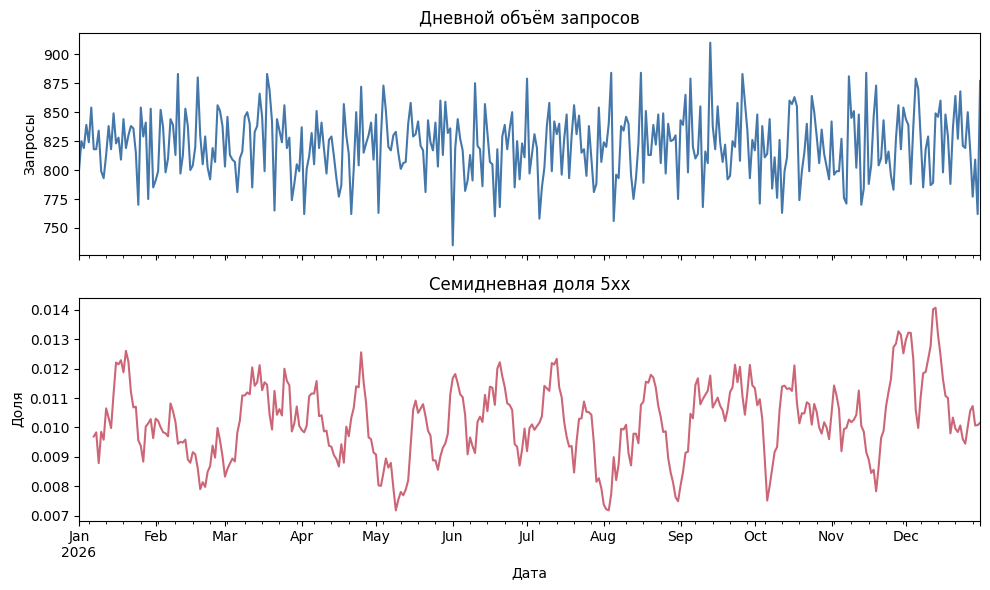

In [16]:
# Шаг 03.16 — Нарисовать объём и долю
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
daily['запросов'].plot(ax=axes[0], color='#4477aa')
axes[0].set(title='Дневной объём запросов', ylabel='Запросы')
daily['доля_5xx_7д'].plot(ax=axes[1], color='#cc6677')
axes[1].set(title='Семидневная доля 5xx', xlabel='Дата', ylabel='Доля')
fig.tight_layout()
fig.savefig(plot_dir / '03_время.png', dpi=130)
plt.show()
plt.close(fig)

Дневные и минутные окна отвечают на разные вопросы; неполные скользящие окна остаются неопределёнными.

## Строковые операции и задачи

Небольшой пример URL покажет разбор параметров. Затем рассматриваются три прикладные задачи.

**Развернуть параметры URL**

В основном журнале пути простые, поэтому используется отдельный небольшой пример с query string. Сначала путь отделяется от параметров, затем разбиваются пары ключ=значение и применяется explode. Одна строка URL может превратиться в несколько строк параметров: единица наблюдения меняется. Если после этого бездумно считать получившиеся строки как запросы, знаменатель будет неверен. Выполняется структурный разбор текста без анализа содержания поисковых слов; NLP находится за пределами этой темы. Настоящие URL с кодированием, повторными ключами и пустыми значениями потребовали бы специального парсера.

In [17]:
# Шаг 03.17 — Развернуть параметры URL
url_example = pd.Series(['/search?q=pandas&sort=new', '/products?id=42&id=43', '/help'], name='url')
url_parts = url_example.str.split('?', n=1, expand=True)
url_frame = pd.DataFrame({'путь': url_parts[0], 'query': url_parts[1]})
url_frame['пары'] = url_frame['query'].fillna('').str.split('&')
query_pairs = url_frame.explode('пары')
query_pairs = query_pairs[query_pairs['пары'].ne('')].copy()
query_pairs[['ключ', 'значение']] = query_pairs['пары'].str.split('=', n=1, expand=True)
display(url_frame[['путь', 'query']])
display(query_pairs[['путь', 'ключ', 'значение']])

,путь,query
0,/search,q=pandas&sort=new
1,/products,id=42&id=43
2,/help,None


,путь,ключ,значение
0,/search,q,pandas
0,/search,sort,new
1,/products,id,42
1,/products,id,43


**Решить задачу о загруженном часе**

Определяется час с максимальным количеством валидных запросов. Временные метки округляются до начала часа, записи подсчитываются, затем выбирается максимум. Это описание данного файла и его записанного календаря, а не оценка числа посетителей. При равенстве idxmax возвращает одно первое максимальное значение; если нужны все лидеры, понадобится фильтр по максимуму. Ячейка содержит решение вместе с результатом, чтобы можно было проверить формулировку и вычисление без отдельного запуска. Обратите внимание: максимальный час выбирается из данных набора, а не относительно сегодняшней даты.

In [18]:
# Шаг 03.18 — Решить задачу о загруженном часе
hourly_load = log.groupby(log['timestamp'].dt.floor('h')).size().rename('запросов')
peak_hour = hourly_load.idxmax()
print('Час максимальной нагрузки:', peak_hour, 'запросов:', int(hourly_load.loc[peak_hour]))
display(hourly_load.nlargest(5).to_frame())

Час максимальной нагрузки: 2026-06-04 01:00:00 запросов: 58


,запросов
timestamp,
2026-06-04 01:00:00,58
2026-12-01 11:00:00,58
2026-08-21 19:00:00,57
2026-10-28 23:00:00,57
2026-03-18 02:00:00,56


**Решить задачу о p95 путей**

Для каждого пути вычисляются число запросов и p95 задержки, затем остаются пути с учебным минимальным объёмом. Это защищает рейтинг от совсем маленьких групп, но не даёт автоматической статистической гарантии. Ранжирование не объясняет причину задержки: на неё могут влиять состав операций, размер ответа и нагрузка. Общий p95 нельзя восстановить усреднением p95 отдельных путей, поскольку перцентиль нелинеен. В выполненном результате виден и порог включения, и обе колонки, нужные для чтения. Такой рейтинг можно использовать как направление для дальнейшей диагностики, а не как окончательный диагноз.

In [19]:
# Шаг 03.19 — Решить задачу о p95 путей
by_path = log.groupby('path')['response_ms'].agg(
    запросов='size', p95_мс=lambda s: s.quantile(.95))
minimum = 100
eligible = by_path[by_path['запросов'] >= minimum].sort_values('p95_мс', ascending=False)
print('Учебный порог запросов:', minimum)
display(eligible.head(10))

Учебный порог запросов: 100


,запросов,p95_мс
path,,
/,60168,337.00
/search,44950,337.00
/checkout,11982,336.00
/cart,24190,335.55
/help,6031,334.50
/account,17791,333.00
/promo,14886,333.00
/catalog,53882,331.00


**Решить задачу о 5xx по браузерам**

В последней задаче для каждой метки browser подсчитываются запросы и ответы 5xx. Доля делит эти два числа внутри одной группы. Она описывает зарегистрированные ответы с данной меткой, а не надёжность браузерной программы и не конверсию пользователей. Различия могут зависеть от путей или синтетической генерации данных. Для контроля сумма групповых числителей должна совпасть с общим числом 5xx; такая сверка проверяет, что группировка не потеряла строки. Даже после неё причинный вывод делать нельзя: правильная арифметика не заменяет дизайна наблюдения. Выполненный результат завершает путь от сырого текста к интерпретируемому показателю.

In [20]:
# Шаг 03.20 — Решить задачу о 5xx по браузерам
browser_errors = log.groupby('browser').agg(
    запросов=('status', 'size'),
    ответов_5xx=('status', lambda s: s.between(500, 599).sum()))
browser_errors['доля_5xx'] = browser_errors['ответов_5xx'] / browser_errors['запросов']
assert int(browser_errors['ответов_5xx'].sum()) == n_5xx
display(browser_errors.sort_values('доля_5xx', ascending=False))

,запросов,ответов_5xx,доля_5xx
browser,,,
bot,15068,194,0.012875
Safari,59776,625,0.010456
YaBrowser,45279,465,0.010270
Edge,21003,213,0.010141
Firefox,23964,238,0.009932
Chrome,134910,1333,0.009881


В каждом решении единица наблюдения и знаменатель остаются явными.

Разбор завершён проверенными агрегатами и тремя решёнными задачами. Для нового источника сначала необходимо уточнить формат, смысл полей и полноту записи; затем повторить валидацию и только после этого интерпретировать графики. Особое внимание требуется к единице наблюдения, пустым интервалам и знаменателю каждой доли.